In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RESULTS_DIR = Path("../results")

In [51]:
run_rows, step_rows = [], []
for run_dir in sorted(RESULTS_DIR.iterdir()):
    config_path, results_path = run_dir / "config.json", run_dir / "results.jsonl"
    if not results_path.exists():
        continue
    config = json.loads(config_path.read_text()) if config_path.exists() else {}
    for line in results_path.read_text().splitlines():
        if not line.strip():
            continue
        rec = json.loads(line)
        steps = rec.pop("steps")
        run_id = f"{run_dir.name}/{rec['trial_name']}"
        run_rows.append({"run_id": run_id, "run_dir": run_dir.name, "cluster": config.get("cluster"),
                         "k": config.get("k"), "align": config.get("align"), **rec, "n_steps": len(steps)})
        for s in steps:
            raw = s.pop("raw") or {}
            step_rows.append({"run_id": run_id, "backend": rec["backend"], "model_name": rec["model_name"],
                              "label": rec["label"], **s,
                              **({f"p_{k}": v for k, v in raw.get("probabilities", {}).items()} if isinstance(raw, dict) else {})})

runs = pd.DataFrame(run_rows)
steps = pd.DataFrame(step_rows)
empty = [d.name for d in RESULTS_DIR.iterdir() if d.is_dir() and d.name not in set(runs["run_dir"])]
print(f"{len(runs)} runs, {len(steps)} steps; result dirs with no rows: {empty}")
runs.head()

100 runs, 845 steps; result dirs with no rows: []


,run_id,run_dir,cluster,k,align,trial_name,model_name,agent_name,task_name,backend,...,label,final_decision,forced,stop_step,stop_agent_turn,items_seen,frac_seen,total_latency_s,correct,n_steps
0,jev-latest_sliding5_choice_b12_claude-haiku-4-...,jev-latest_sliding5_choice_b12_claude-haiku-4-...,SOPHIA,5,event,anuraghazra__githubreadmestats16__aNkQMao,claude-haiku-4-5-20251001,claude-code,anuraghazra__githubreadmestats1608,jev-latest,...,True,NO,False,36,34,368,0.773109,4.511002,False,37
1,jev-latest_sliding5_choice_b12_claude-opus-4-6...,jev-latest_sliding5_choice_b12_claude-opus-4-6...,SOPHIA,5,event,anuraghazra__githubreadmestats16__7Fcx5ou,claude-opus-4-6,claude-code,anuraghazra__githubreadmestats1608,jev-latest,...,False,YES,False,22,15,235,1.000000,2.996978,False,23
2,jev-latest_sliding5_choice_b12_claude-sonnet-4...,jev-latest_sliding5_choice_b12_claude-sonnet-4...,SOPHIA,5,event,astropy__astropy-12907__EWnwaYU,claude-sonnet-4-6,claude-code,astropy__astropy-12907,jev-latest,...,True,YES,True,8,9,85,1.000000,1.174498,True,9
3,jev-latest_sliding5_choice_b12_deepseek-chat__...,jev-latest_sliding5_choice_b12_deepseek-chat__...,SOPHIA,5,event,anuraghazra__githubreadmestats10__c6mBmur,deepseek-chat,claude-code,anuraghazra__githubreadmestats105,jev-latest,...,False,YES,False,87,87,880,0.854369,9.171123,False,88
4,jev-latest_sliding5_choice_b12_deepseek-reason...,jev-latest_sliding5_choice_b12_deepseek-reason...,SOPHIA,5,event,astropy__astropy-12907__vgdqNJ7,deepseek-reasoner,terminus-2,astropy__astropy-12907,jev-latest,...,True,YES,False,23,12,256,0.661499,2.897276,True,24


In [52]:
runs[["backend", "model_name", "task_name", "label", "final_decision", "forced", "correct",
      "stop_step", "frac_seen", "total_latency_s"]]

,backend,model_name,task_name,label,final_decision,forced,correct,stop_step,frac_seen,total_latency_s
0,jev-latest,claude-haiku-4-5-20251001,anuraghazra__githubreadmestats1608,True,NO,False,False,36,0.773109,4.511002
1,jev-latest,claude-opus-4-6,anuraghazra__githubreadmestats1608,False,YES,False,False,22,1.000000,2.996978
2,jev-latest,claude-sonnet-4-6,astropy__astropy-12907,True,YES,True,True,8,1.000000,1.174498
3,jev-latest,deepseek-chat,anuraghazra__githubreadmestats105,False,YES,False,False,87,0.854369,9.171123
4,jev-latest,deepseek-reasoner,astropy__astropy-12907,True,YES,False,True,23,0.661499,2.897276
...,...,...,...,...,...,...,...,...,...,...
95,openai/gpt-oss-20b,gpt-5-nano,anuraghazra__githubreadmestats117,False,YES,True,False,2,1.000000,10.975132
96,openai/gpt-oss-20b,gpt-5.4,anuraghazra__githubreadmestats117,False,YES,False,False,0,0.285714,3.208763
97,openai/gpt-oss-20b,kimi-k2.5,astropy__astropy-12907,True,YES,False,True,0,0.104803,3.131104
98,openai/gpt-oss-20b,mimo-v2-pro,astropy__astropy-12907,True,YES,False,True,0,0.247475,2.205333


In [53]:
GROUP_COLS = ["backend", "bag", "batch_size", "align", "policy"]
runs.groupby(GROUP_COLS, dropna=False).agg(
    n=("run_id", "size"),
    accuracy=("correct", "mean"),
    forced_rate=("forced", "mean"),
    mean_frac_seen=("frac_seen", "mean"),
    mean_steps=("n_steps", "mean"),
    mean_latency_s=("total_latency_s", "mean"),
)

n  \
backend             bag             batch_size align policy                               
jev-latest          SlidingBag(k=5) 12         event ChoicePolicy()                  14   
                                    30         event ThresholdPolicy(threshold=0.8)  14   
                    SlidingBag(k=6) 100        event ThresholdPolicy(threshold=0.8)  14   
openai/gpt-oss-120b SlidingBag(k=5) 25         event ChoicePolicy()                  14   
openai/gpt-oss-20b  SlidingBag(k=5) 25         event ChoicePolicy()                  14   
                    SlidingBag(k=8) 35         event ChoicePolicy()                  15   
                                    50         event ChoicePolicy()                  15   

                                                                                     accuracy  \
backend             bag             batch_size align policy                                     
jev-latest          SlidingBag(k=5) 12         event ChoicePolicy()                  0.428571   
                                    30         event ThresholdPolicy(threshold=0.8)       0.5   
                    SlidingBag(k=6) 100        event ThresholdPolicy(threshold=0.8)     0.375   
openai/gpt-oss-120b SlidingBag(k=5) 25         event ChoicePolicy()                  0.357143   
openai/gpt-oss-20b  SlidingBag(k=5) 25         event ChoicePolicy()                  0.857143   
                    SlidingBag(k=8) 35         event ChoicePolicy()                  0.666667   
                                    50         event ChoicePolicy()                       0.6   

                                                                                     forced_rate  \
backend             bag             batch_size align policy                                        
jev-latest          SlidingBag(k=5) 12         event ChoicePolicy()                     0.285714   
                                    30         event ThresholdPolicy(threshold=0.8)     0.357143   
                    SlidingBag(k=6) 100        event ThresholdPolicy(threshold=0.8)     0.642857   
openai/gpt-oss-120b SlidingBag(k=5) 25         event ChoicePolicy()                     0.071429   
openai/gpt-oss-20b  SlidingBag(k=5) 25         event ChoicePolicy()                     0.000000   
                    SlidingBag(k=8) 35         event ChoicePolicy()                     0.000000   
                                    50         event ChoicePolicy()                     0.066667   

                                                                                     mean_frac_seen  \
backend             bag             batch_size align policy                                           
jev-latest          SlidingBag(k=5) 12         event ChoicePolicy()                        0.784160   
                                    30         event ThresholdPolicy(threshold=0.8)        0.829676   
                    SlidingBag(k=6) 100        event ThresholdPolicy(threshold=0.8)        0.982172   
openai/gpt-oss-120b SlidingBag(k=5) 25         event ChoicePolicy()                        0.626738   
openai/gpt-oss-20b  SlidingBag(k=5) 25         event ChoicePolicy()                        0.351627   
                    SlidingBag(k=8) 35         event ChoicePolicy()                        0.342168   
                                    50         event ChoicePolicy()                        0.404916   

                                                                                     mean_steps  \
backend             bag             batch_size align policy                                       
jev-latest          SlidingBag(k=5) 12         event ChoicePolicy()                   28.857143   
                                    30         event ThresholdPolicy(threshold=0.8)    9.642857   
                    SlidingBag(k=6) 100        event ThresholdPolicy(threshold=0.8)    3.928571   
openai/gpt-oss-120b SlidingBag(k=5) 25         event ChoicePolicy() 

In [45]:
pd.crosstab(runs["label"], runs["final_decision"], margins=True)

final_decision,NO,UNSURE,YES,All
label,,,,
False,13,2,25,40
True,6,4,20,30
All,19,6,45,70


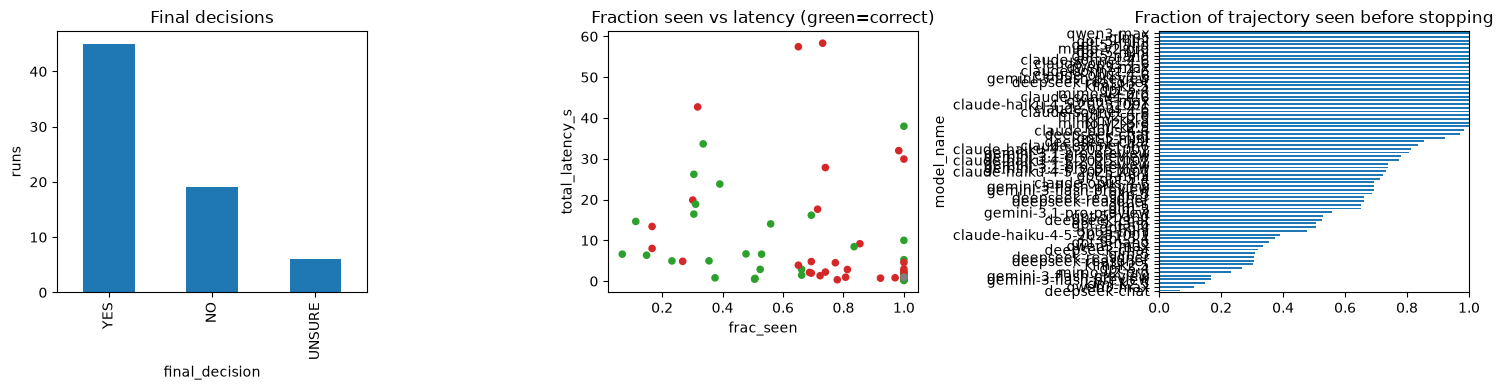

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

runs["final_decision"].value_counts().plot.bar(ax=axes[0], title="Final decisions")
axes[0].set_ylabel("runs")

runs.plot.scatter(x="frac_seen", y="total_latency_s", c=runs["correct"].map({True: "tab:green", False: "tab:red"}).fillna("gray"),
                  ax=axes[1], title="Fraction seen vs latency (green=correct)")

runs.set_index("model_name")["frac_seen"].sort_values().plot.barh(ax=axes[2], title="Fraction of trajectory seen before stopping")
axes[2].set_xlim(0, 1)

plt.tight_layout()

/tmp/ipykernel_7205/911526062.py:8: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


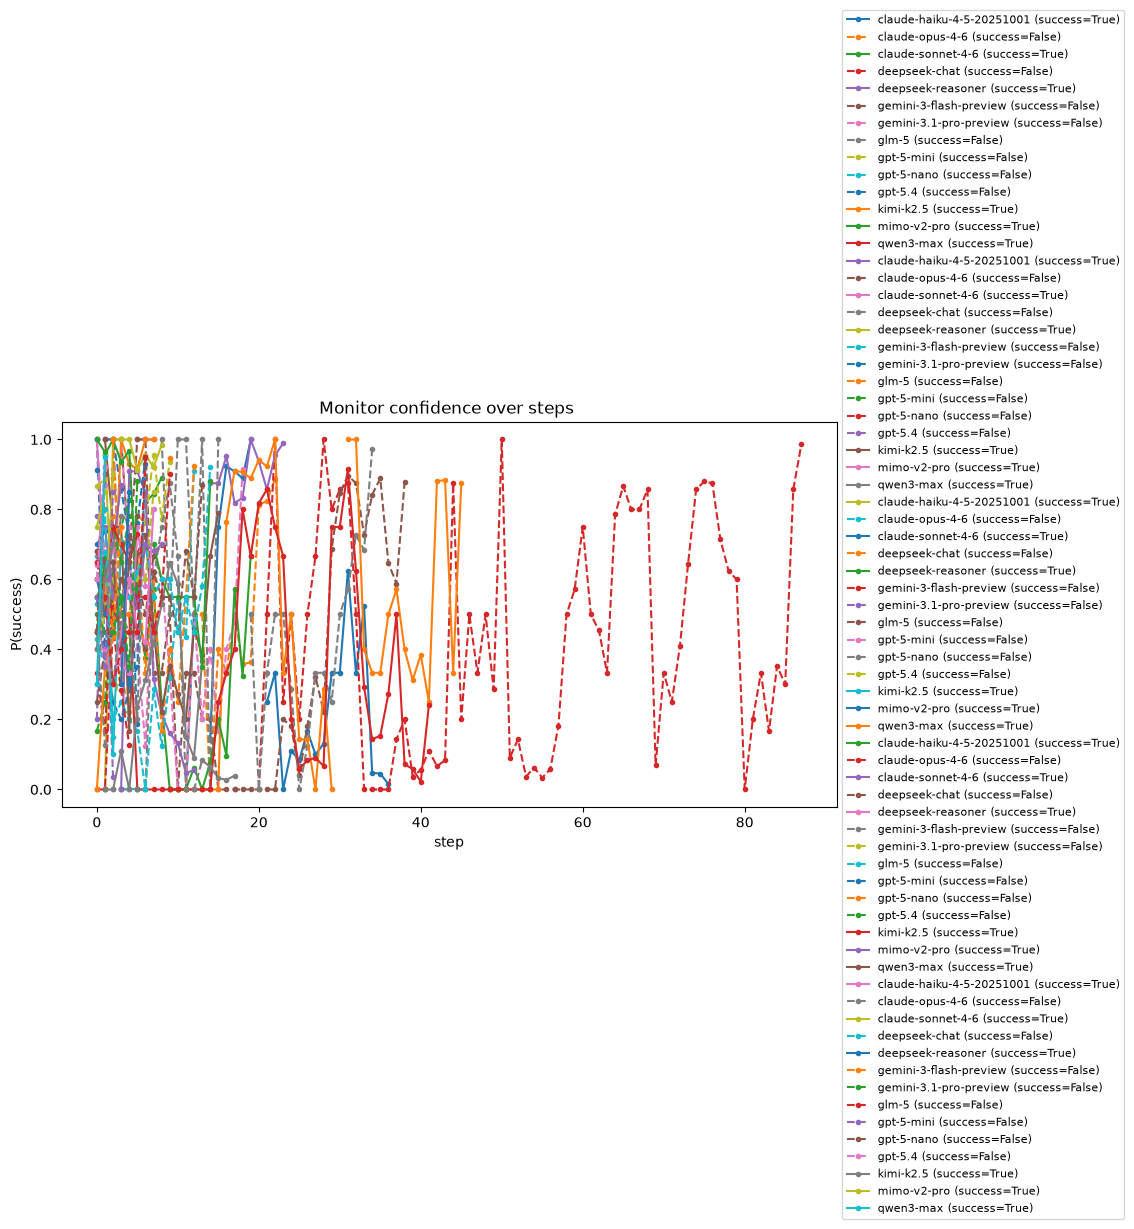

In [47]:
fig, ax = plt.subplots(figsize=(10, 5))
for run_id, g in steps.groupby("run_id"):
    label = g["label"].iloc[0]
    ax.plot(g["t"], g["confidence"], marker=".", linestyle="-" if label else "--",
            label=f"{g['model_name'].iloc[0]} (success={label})")
ax.set(xlabel="step", ylabel="P(success)", title="Monitor confidence over steps ", ylim=(-0.05, 1.05))
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()

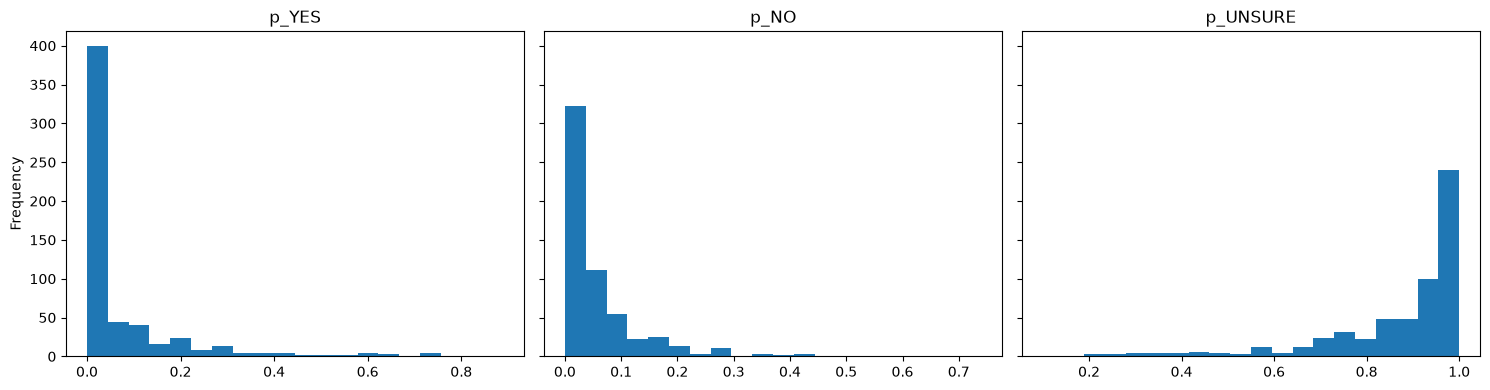

In [41]:
prob_cols = [c for c in ["p_YES", "p_NO", "p_UNSURE"] if c in steps.columns]
if prob_cols:
    fig, axes = plt.subplots(1, len(prob_cols), figsize=(5 * len(prob_cols), 4), sharey=True)
    for ax, col in zip(axes, prob_cols):
        steps[col].plot.hist(bins=20, ax=ax, title=col)
    plt.tight_layout()